# EDA: chamados de iluminação por bairro (Grupo 17)

Análise complementar com dados reais da Emlurb: cadastro de postes de 2025 e chamados da Central 156
de 2022–2025. A unidade é bairro × mês; o alvo é a contagem de chamados do mês seguinte.
O modelo principal do projeto, de falha por luminária em 14 dias com dados simulados, está no notebook 03.

Execute este notebook a partir de `applications/ml/notebooks/`, com as dependências da central,
`matplotlib` e Jupyter instalados. Usa somente os CSVs processados versionados.
Fonte das regras e dos registros históricos de limpeza: [`../src/preparar_dados.py`](../src/preparar_dados.py)
e [`../README.md`](../README.md).

In [1]:
import matplotlib.pyplot as plt
import pandas as pd

pd.set_option("display.max_columns", None)

PALETA = {
    "primaria": "#2E6F8E",   # azul principal (series unica)
    "secundaria": "#6C757D", # cinza para contraste/comparacao
    "alerta": "#C1502E",     # usado so para destacar o achado da secao 1
}
plt.rcParams.update({
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.25,
    "grid.linewidth": 0.6,
    "figure.dpi": 110,
})

In [2]:
painel = pd.read_csv("../data/processed/risco_bairro_mes.csv")
postes = pd.read_csv("../data/processed/postes_por_bairro.csv")

print("painel (bairro x mes):", painel.shape)
print("postes_por_bairro:", postes.shape)
painel.head()

painel (bairro x mes): (4136, 15)
postes_por_bairro: (94, 6)


,bairro_norm,ano_mes,chamados_lampada_apagada,total_postes,postes_sem_id,potencia_media_w,pct_led,rpa,chamados_lag1,chamados_lag2,chamados_lag3,media_movel_3m,teve_chamado_mes_seguinte,chamados_mes_seguinte,conjunto
0,AFLITOS,2022-04,4,304.0,163.0,69.0,100.0,2,8.0,2.0,4.0,4.666667,1,2,treino
1,AFLITOS,2022-05,2,304.0,163.0,69.0,100.0,2,4.0,8.0,2.0,4.666667,1,5,treino
2,AFLITOS,2022-06,5,304.0,163.0,69.0,100.0,2,2.0,4.0,8.0,4.666667,1,5,treino
3,AFLITOS,2022-07,5,304.0,163.0,69.0,100.0,2,5.0,2.0,4.0,3.666667,1,5,treino
4,AFLITOS,2022-08,5,304.0,163.0,69.0,100.0,2,5.0,5.0,2.0,4.000000,1,1,treino


## 0. Limpeza, normalização e qualidade dos dados

Os CSVs brutos ficam fora do Git e **não foram relidos nesta execução**. Os números históricos abaixo
foram registrados no README de ML; as tabelas seguintes são calculadas agora a partir dos CSVs processados.

| Etapa no `preparar_dados.py` | Regra e evidência histórica |
|---|---|
| Leitura e duplicatas | CSV com `sep=";"` e `dtype=str`; chamados concatenados e `drop_duplicates()` antes do filtro. Sem brutos, não recalculamos quantas duplicatas saíram. |
| Códigos de serviço | Filtrar os pares grupo/serviço `17/25` e `4/55`. O texto descritivo tem acentos corrompidos em 2022–2023. |
| Datas | `pd.to_datetime(DATA_DEMANDA, errors="coerce")`; contar e descartar `NaT`, restringir a 2022-01–2025-12. O registro anterior exige zero datas inválidas; isso não é uma nova medição dos brutos. |
| Cadastro desalinhado | Excluir bairro com dígitos ou nulo; foi registrada 1 linha inválida entre 111.666. |
| Postes sem ID | Preservar os postes sem `id_ponto`; contar com `size`, registrar ausência em `postes_sem_id`. A quantidade atual é calculada abaixo. |
| Bairros | Remover acentos, uniformizar caixa/espaços e corrigir três grafias; exemplos executáveis abaixo. |
| Bairro não informado | Excluir `BAIRRO NAO INFORMADO`; o README registra 54 chamados. |
| Cruzamento | Agregar por bairro; excluir três nomes de chamados sem correspondência no cadastro (144 linhas bairro × mês antes dos demais cortes, segundo o README). |
| Nulos e números | Converter potência com vírgula decimal, usando `to_numeric(errors="coerce")`; média por bairro ignora nulos. Excluir `consumo_kw`/`consumo_1`, cuja qualidade é inadequada. |
| Histórico e alvo | Completar meses sem chamados com zero; criar lags 1/2/3 e média dos três meses anteriores. Retirar os três meses iniciais sem histórico e o último mês sem alvo. |
| Separação temporal | Separar pelo mês **do alvo**, nunca aleatoriamente: alvos até 2024-12 no treino e alvos de 2025 no teste. |

Ausência em `id_ponto` não equivale a ausência de poste. Zero chamados no painel completo não equivale
a um valor de sensor ausente. Esses casos recebem tratamentos diferentes no pipeline.

In [3]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path("../src").resolve()))
from preparar_dados import normalizar_bairro

exemplos = ["  Boa   Viagem ", "Graças", "CIDADDE UNIVERSITARIA", "IMBIRBEIRA", "TEJIIPIO", None]
display(pd.DataFrame({"entrada": exemplos, "bairro_normalizado": [normalizar_bairro(x) for x in exemplos]}))
print("Postes contabilizados:", int(postes["total_postes"].sum()))
print("Postes sem ID:", int(postes["postes_sem_id"].sum()))
print("Proporção sem ID:", f"{postes['postes_sem_id'].sum() / postes['total_postes'].sum():.2%}")
print("Bairros:", painel["bairro_norm"].nunique(), "| meses:", painel["ano_mes"].nunique())
print("Período observado:", painel["ano_mes"].min(), "a", painel["ano_mes"].max())
display(pd.DataFrame({"tipo": painel.dtypes.astype(str), "nulos": painel.isna().sum()}))
display(painel.groupby("conjunto").agg(linhas=("ano_mes", "size"), inicio=("ano_mes", "min"), fim=("ano_mes", "max")))
assert not painel.duplicated(["bairro_norm", "ano_mes"]).any()
assert not painel.isna().any().any()
assert set(painel["bairro_norm"]) == set(postes["bairro_norm"])
assert "BAIRRO NAO INFORMADO" not in set(painel["bairro_norm"])
mes_alvo = (pd.PeriodIndex(painel["ano_mes"], freq="M") + 1).astype(str)
assert (mes_alvo[painel["conjunto"] == "treino"] <= "2024-12").all()
assert (mes_alvo[painel["conjunto"] == "teste"] >= "2025-01").all()

,entrada,bairro_normalizado
0,Boa Viagem,BOA VIAGEM
1,Graças,GRACAS
2,CIDADDE UNIVERSITARIA,CIDADE UNIVERSITARIA
3,IMBIRBEIRA,IMBIRIBEIRA
4,TEJIIPIO,TEJIPIO
5,None,


Postes contabilizados: 111665
Postes sem ID: 7098
Proporção sem ID: 6.36%
Bairros: 94 | meses: 44
Período observado: 2022-04 a 2025-11


,tipo,nulos
bairro_norm,object,0
ano_mes,object,0
chamados_lampada_apagada,int64,0
total_postes,float64,0
postes_sem_id,float64,0
potencia_media_w,float64,0
pct_led,float64,0
rpa,int64,0
chamados_lag1,float64,0
chamados_lag2,float64,0


,linhas,inicio,fim
conjunto,,,
teste,1128,2024-12,2025-11
treino,3008,2022-04,2024-11


### Features e encoding no treino

`treinar.carregar()` deriva `taxa_1000_postes` e o mês do ano. O pré-processamento é ajustado somente
na partição usada em cada treino: no GLM de Poisson, as dez features contínuas recebem `log1p` e
padronização; `rpa` recebe one-hot com categorias desconhecidas ignoradas; o mês recebe seno/cosseno,
preservando a proximidade dezembro–janeiro. A baseline linear usa contínuas padronizadas sem log;
os modelos de árvore usam as contínuas sem essa transformação. RPA não é uma medida ordinal.
Nenhuma transformação deve ser ajustada no teste final.

## 1. Chamados de "lâmpada apagada" por mês

Primeiro achado, antes de qualquer modelo: o volume de chamados **não é estável no período**.

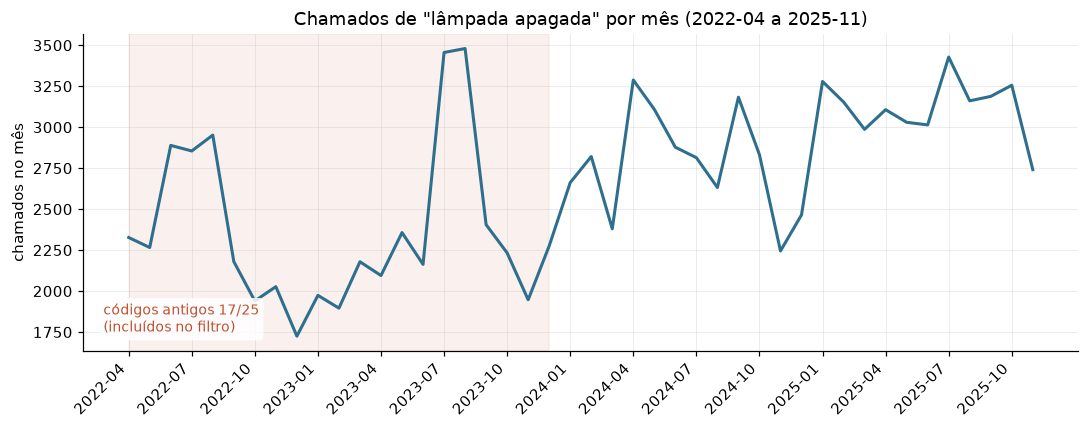

In [4]:
mensal = painel.groupby("ano_mes")["chamados_lampada_apagada"].sum()

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(mensal.index, mensal.values, color=PALETA["primaria"], linewidth=2)
ax.axvspan(0, mensal.index.get_loc("2023-12"), color=PALETA["alerta"], alpha=0.08)
ax.set_title('Chamados de "lâmpada apagada" por mês (2022-04 a 2025-11)')
ax.set_ylabel("chamados no mês")
ax.set_xticks(range(0, len(mensal), 3))
ax.set_xticklabels(mensal.index[::3], rotation=45, ha="right")
ax.text(
    0.02, 0.06, "códigos antigos 17/25\n(incluídos no filtro)",
    transform=ax.transAxes, fontsize=9, color=PALETA["alerta"],
    bbox=dict(boxstyle="round,pad=0.3", facecolor="white", edgecolor="none", alpha=0.85),
)
plt.tight_layout()
plt.show()

**O que o gráfico mostra (texto revisado em 25/11):** a área sombreada marca 2022-2023, a era dos
códigos antigos de serviço (`GRUPOSERVICO_CODIGO`/`SERVICO_CODIGO` = `17`/`25`; em 2024 viraram `4`/`55`,
e o texto descritivo de 2022-2023 vem com a acentuação corrompida). O `preparar_dados.py` filtra pelos
**dois** pares de código, então esses anos **não ficam perto de zero**: a base processada tem cerca de
**1.700 a 3.500 chamados por mês em 2022-2023** e **2.200 a 3.400 em 2024-2025**. Ver seção 2 do
[`applications/ml/README.md`](../README.md).

> Uma versão anterior deste texto dizia que 2022-2023 ficava "quase em zero". Isso era antes de o filtro
> pelos dois códigos existir e não vale mais.

**Implicação para a modelagem:** o volume cresce de ~2.350 chamados/mês (abr-dez/2022) para ~3.100
(2025), uma tendência de alta, mas sem quebra. Não há motivo para tirar 2022-2023 do treino. Vale só
testar se o modelo melhora treinando a partir de 2023 ou de 2024, e registrar a comparação no MLflow.

## 2. Chamados por bairro — top 10 e bottom 10

Onde o problema se concentra, somando os 44 meses disponíveis no painel.

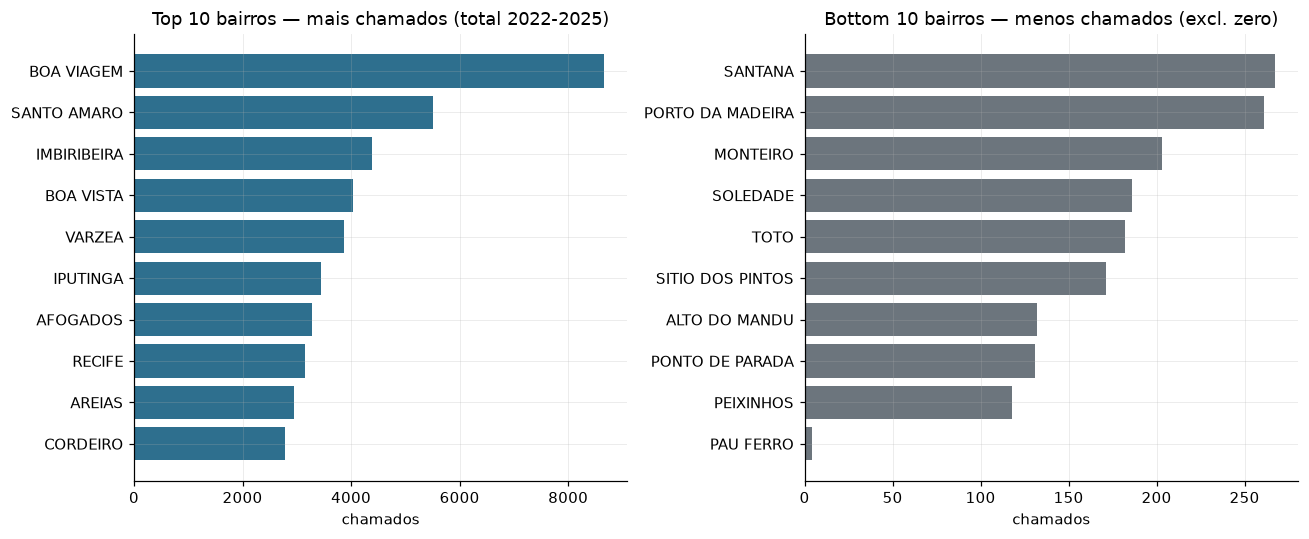

Bairros com ZERO chamados de lâmpada apagada no período inteiro: 0 de 94


In [5]:
por_bairro = painel.groupby("bairro_norm")["chamados_lampada_apagada"].sum().sort_values(ascending=False)
top10 = por_bairro.head(10)
bottom10 = por_bairro[por_bairro > 0].tail(10)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].barh(top10.index[::-1], top10.values[::-1], color=PALETA["primaria"])
axes[0].set_title("Top 10 bairros — mais chamados (total 2022-2025)")
axes[0].set_xlabel("chamados")

axes[1].barh(bottom10.index[::-1], bottom10.values[::-1], color=PALETA["secundaria"])
axes[1].set_title("Bottom 10 bairros — menos chamados (excl. zero)")
axes[1].set_xlabel("chamados")

plt.tight_layout()
plt.show()

zerados = (por_bairro == 0).sum()
print(f"Bairros com ZERO chamados de lâmpada apagada no período inteiro: {zerados} de {len(por_bairro)}")

**Leitura:** a distribuição é bem concentrada — alguns bairros carregam uma fração grande dos
chamados totais, o que é esperado (bairros maiores, mais populosos ou com mais postes tendem a gerar
mais chamados em termos absolutos). Isso sugere que o modelo pode se beneficiar de uma feature de
**exposição** (total de postes do bairro, já disponível em `total_postes`) para não confundir "bairro
grande" com "bairro de risco".

## 3. Tipo de lâmpada e % de LED por bairro

O cadastro de postes (2025) mostra o quanto cada bairro já migrou para LED.

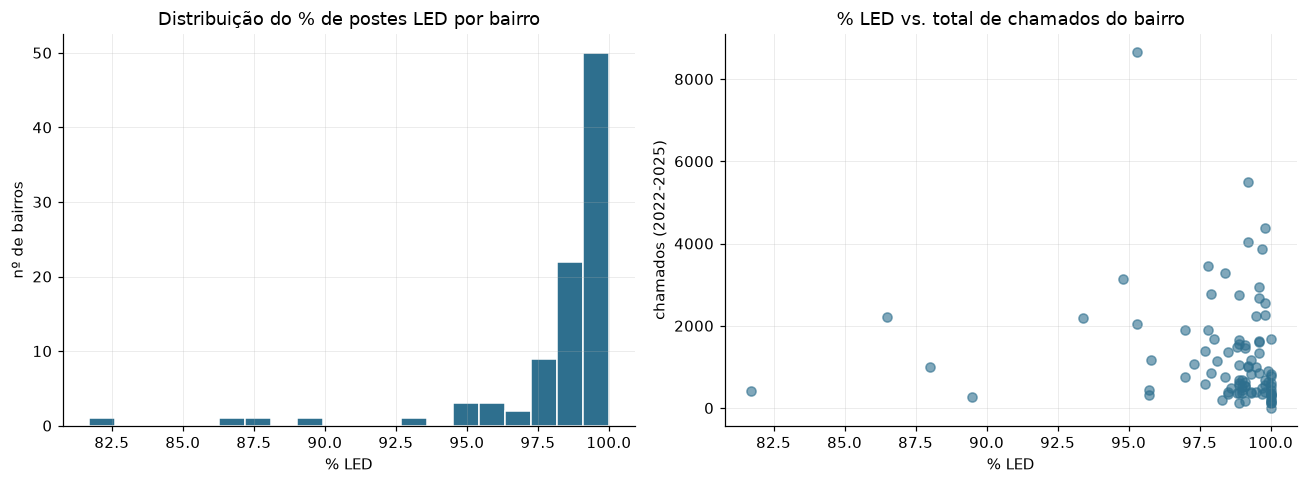

% LED médio entre bairros: 98.3
% LED mínimo: 81.7 | máximo: 100.0


In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

axes[0].hist(postes["pct_led"], bins=20, color=PALETA["primaria"], edgecolor="white")
axes[0].set_title("Distribuição do % de postes LED por bairro")
axes[0].set_xlabel("% LED")
axes[0].set_ylabel("nº de bairros")

chamados_total = painel.groupby("bairro_norm")["chamados_lampada_apagada"].sum()
comparacao = postes.set_index("bairro_norm").join(chamados_total.rename("chamados_total"))

axes[1].scatter(comparacao["pct_led"], comparacao["chamados_total"], color=PALETA["primaria"], alpha=0.6)
axes[1].set_title("% LED vs. total de chamados do bairro")
axes[1].set_xlabel("% LED")
axes[1].set_ylabel("chamados (2022-2025)")

plt.tight_layout()
plt.show()

print("% LED médio entre bairros:", round(postes["pct_led"].mean(), 1))
print("% LED mínimo:", postes["pct_led"].min(), "| máximo:", postes["pct_led"].max())

**Leitura:** a maior parte dos bairros já está com % de LED bem alto (mediana alta, poucos bairros
destoando para baixo) — a cidade já avançou bastante na troca para LED. Não há uma relação linear
óbvia entre `% LED` e volume de chamados no gráfico de dispersão (o volume de chamados parece dominado
pelo tamanho do bairro, não pela tecnologia da lâmpada) — mas vale deixar `pct_led` como feature e
deixar o modelo decidir, em vez de descartar a priori.

## 4. Balanço da classe do rótulo (`teve_chamado_mes_seguinte`)

Esse é o ponto mais importante para a modelagem: como o rótulo binário se comporta por conjunto.

          proporcao_positiva  n_linhas
conjunto                              
teste                  0.952      1128
treino                 0.969      3008


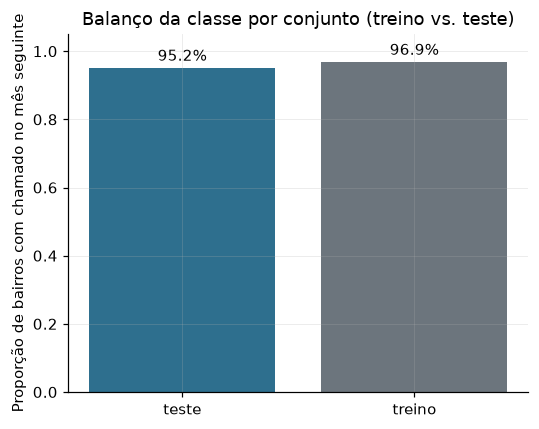

In [7]:
balanco = painel.groupby("conjunto")["teve_chamado_mes_seguinte"].agg(["mean", "count"])
balanco.columns = ["proporcao_positiva", "n_linhas"]
print(balanco.round(3))

fig, ax = plt.subplots(figsize=(5, 4))
cores = [PALETA["primaria"], PALETA["secundaria"]]
ax.bar(balanco.index, balanco["proporcao_positiva"], color=cores)
for i, v in enumerate(balanco["proporcao_positiva"]):
    ax.text(i, v + 0.02, f"{v:.1%}", ha="center", fontsize=10)
ax.set_ylim(0, 1.05)
ax.set_ylabel("Proporção de bairros com chamado no mês seguinte")
ax.set_title("Balanço da classe por conjunto (treino vs. teste)")
plt.tight_layout()
plt.show()

**Leitura:** treino e teste ficam bem próximos um do outro, o que é bom sinal — não há mudança
abrupta de distribuição entre os dois períodos, então o split temporal é razoável.

**Mas atenção:** essa proporção é o **oposto** do desbalanceamento clássico que a disciplina costuma
avisar (rótulo raro). Aqui, "ter pelo menos um chamado no mês seguinte" é o normal, não a exceção —
com ~94 bairros dividindo milhares de chamados por mês, quase todo bairro tem pelo menos um chamado
em quase todo mês. Prever "vai ter chamado" sempre como resposta já acerta a maioria das vezes — a
seção 5 mostra o quanto isso prejudica o classificador binário, e qual alternativa resolve.

## 5. Defasagem (lag) e a decisão de alvo: classificação binária vs. contagem

O `preparar_dados.py` agora inclui features de histórico por bairro (`chamados_lag1/2/3`,
`media_movel_3m`). Antes de escrever o `treinar.py`, a pergunta é: qual alvo essas features
conseguem prever melhor — o binário `teve_chamado_mes_seguinte` ou a contagem bruta
`chamados_mes_seguinte`?

                          correlação com o binário  correlação com a contagem
pct_led                                     -0.075                     -0.085
potencia_media_w                             0.107                      0.091
rpa                                         -0.000                      0.270
total_postes                                 0.038                      0.798
chamados_lag3                                0.126                      0.828
chamados_lag2                                0.133                      0.832
chamados_lag1                                0.139                      0.845
media_movel_3m                               0.139                      0.874
chamados_lampada_apagada                     0.144                      0.885


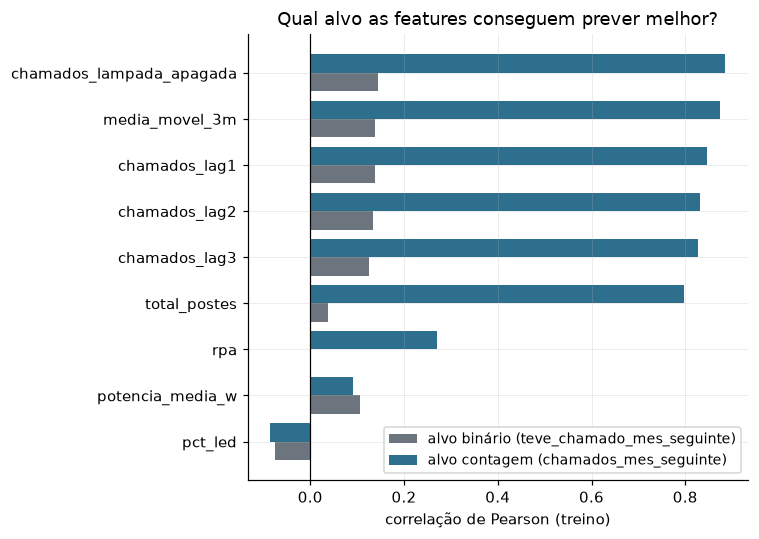

In [8]:
features = [
    "chamados_lampada_apagada", "chamados_lag1", "chamados_lag2", "chamados_lag3",
    "media_movel_3m", "total_postes", "potencia_media_w", "pct_led", "rpa",
]
treino = painel[painel["conjunto"] == "treino"]

corr_binario = treino[features + ["teve_chamado_mes_seguinte"]].corr()["teve_chamado_mes_seguinte"].drop("teve_chamado_mes_seguinte")
corr_contagem = treino[features + ["chamados_mes_seguinte"]].corr()["chamados_mes_seguinte"].drop("chamados_mes_seguinte")

comparacao_alvo = pd.DataFrame({
    "correlação com o binário": corr_binario,
    "correlação com a contagem": corr_contagem,
}).sort_values("correlação com a contagem")

print(comparacao_alvo.round(3))

fig, ax = plt.subplots(figsize=(7, 5))
y = range(len(comparacao_alvo))
ax.barh([p - 0.2 for p in y], comparacao_alvo["correlação com o binário"], height=0.4,
        color=PALETA["secundaria"], label="alvo binário (teve_chamado_mes_seguinte)")
ax.barh([p + 0.2 for p in y], comparacao_alvo["correlação com a contagem"], height=0.4,
        color=PALETA["primaria"], label="alvo contagem (chamados_mes_seguinte)")
ax.set_yticks(list(y))
ax.set_yticklabels(comparacao_alvo.index)
ax.axvline(0, color="black", linewidth=0.8)
ax.set_xlabel("correlação de Pearson (treino)")
ax.set_title("Qual alvo as features conseguem prever melhor?")
ax.legend(loc="lower right", fontsize=9)
plt.tight_layout()
plt.show()

**Resultado:** contra o alvo binário, toda e qualquer feature fica abaixo de 0,15 de correlação —
o sinal linear medido é fraco, inclusive no histórico do bairro; isso não exclui relações não lineares. Contra a **contagem**,
a história é completamente diferente: `chamados_lampada_apagada` do mês atual chega a **0,89**,
`media_movel_3m` a **0,87**, e até `total_postes` (uma feature estática do cadastro) chega a **0,80**.

**Decisão de alvo desta análise complementar: prever a contagem de chamados do mês seguinte
(regressão/ranking), não a classificação binária.** A alta prevalência de ~95% reduz a utilidade operacional desse rótulo neste nível de
agregação (bairro × mês); a contagem
preserva toda a informação que o histórico de chamados carrega. O `treinar.py` deve:

1. Treinar `RandomForestRegressor`/`GradientBoostingRegressor` prevendo `chamados_mes_seguinte`,
   comparando com a baseline simples (`media_movel_3m`, ou "chamados do bairro no ano anterior").
2. Converter a previsão em **risco de 0 a 1** normalizando por percentil entre os bairros do mesmo
   mês (bairro no percentil 90+ de chamados previstos = risco alto) — mantém o contrato já
   documentado no `MACHINE_LEARNING.md` (potência 90/80/70 por faixa de risco).
3. Avaliar com a **"precisão no top 10%"** da seção 4 do `MACHINE_LEARNING.md`, que já é uma métrica
   de ranking — ela se encaixa na regressão de forma muito mais natural do que na classificação
   binária original.

O rótulo binário (`teve_chamado_mes_seguinte`) continua na base, documentado, caso alguém queira
comparar as duas abordagens no relatório — mas não é mais o alvo principal.

## 6. Limitações

- As features estáticas do cadastro de **2025** são aplicadas a chamados de **2022–2025**. Isso supõe
  estabilidade do parque; mudanças anteriores não observadas podem introduzir informação futura
  (*look-ahead*) nas features estáticas. A divisão temporal não elimina essa limitação da fonte.
- Chamados medem registros de demanda por manutenção, não todas as falhas reais. Subnotificação,
  mudanças no atendimento e na classificação do serviço podem alterar o volume observado.
- Correlação baixa com o rótulo binário não prova impossibilidade de classificação; aqui a alta
  prevalência e a maior informação preservada pela contagem motivam a opção por regressão.
- O ranking por taxa por 1.000 postes tem precisão menor (cerca de 0,55–0,57 no top 10% do modelo
  escolhido, conforme a execução). O notebook 02 mostra as métricas exatas. A escolha operacional
  entre contagem e taxa permanece uma decisão do grupo (T5c).
- Os totais históricos de exclusão dos brutos não foram revalidados; esta execução confere a base
  processada. Os gráficos cobrem abril/2022–novembro/2025, após retirar meses sem histórico/alvo.
- A correlação de Pearson com os códigos de RPA é apenas descritiva e depende da codificação;
  não indica ordem entre regiões. O treino usa one-hot para essa variável categórica.